# Feature RMSE check (one time holdout)

Do **not** put `n_primary_within_1km` or `n_mrt_within_1km` into `01_eda_hdb.ipynb`.
They need school/MRT coordinates.

Fit Jan 2021 to Dec 2023, score Jan 2024 to Mar 2025 (inside train, test has no labels).
Models: Linear Regression and LightGBM (`n_estimators=400`, `learning_rate=0.05`,
`num_leaves=31`). ΔRMSE = RMSE(BASE) − RMSE(this set). Positive = better.

BASE: `FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX`, `TOWN`, `FLAT_TYPE`,
`FLAT_MODEL`. BASE RMSE: LR 657, LightGBM 496.4.

1. Build block-level distance features
2. Time split and BASE
3. Single extra features
4. Combinations
5. Drop the 11 incomplete-info blocks?
6. Verdict


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
OUT_DIR = OUT  # matches the alias used by the other EDA notebooks / _run_all.py
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
CUT = pd.Timestamp("2024-01-01")


## 1. Block-level distance features

Haversine count of primary schools and **unique open** MRT station names within 1 km
of each HDB block. Planned stations are excluded.


In [2]:
def lower_strip(df):
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def count_within_1km(block_lat, block_lon, poi_lat, poi_lon):
    d = haversine_km(
        block_lat[:, None], block_lon[:, None], poi_lat[None, :], poi_lon[None, :]
    )
    return (d <= 1.0).sum(axis=1)


train = pd.read_csv(DATA / "train.csv")
hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv")
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
mrt_area = pd.read_csv(OUT / "mrt_features_by_area.csv")
school_area = pd.read_csv(OUT / "school_features_by_area.csv")

primary = schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)]
mrt_open = mrt.loc[mrt["STATUS"].eq("open"), ["NAME", "LATITUDE", "LONGITUDE"]].drop_duplicates("NAME")

hdb = hdb.copy()
hdb["n_primary_within_1km"] = count_within_1km(
    hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy(),
    primary["LATITUDE"].to_numpy(), primary["LONGITUDE"].to_numpy(),
)
hdb["n_mrt_within_1km"] = count_within_1km(
    hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy(),
    mrt_open["LATITUDE"].to_numpy(), mrt_open["LONGITUDE"].to_numpy(),
)
print("primary schools:", len(primary), "  unique open MRT names:", len(mrt_open))
print(hdb[["n_primary_within_1km", "n_mrt_within_1km"]].describe().T)


primary schools: 179   unique open MRT names: 192
                         count  mean   std   min   25%   50%   75%    max
n_primary_within_1km 9,464.000 3.029 1.561 0.000 2.000 3.000 4.000 10.000
n_mrt_within_1km     9,464.000 1.553 1.064 0.000 1.000 1.000 2.000 10.000


## 2. Analysis frame, time split, BASE

`FURNISHED` and `FEE` are constant and dropped. Flat type `"4 room"` / `"4-room"` is one
category. Text is lowercased before the HDB join.

BASE numerics: `FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX`.
BASE categoricals: `TOWN`, `FLAT_TYPE`, `FLAT_MODEL`.


In [3]:
def clean_rent(df):
    out = lower_strip(df)
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["MONTH_INDEX"] = (out["RENT_APPROVAL_DATE"].dt.year - 2021) * 12 + out["RENT_APPROVAL_DATE"].dt.month - 1
    out["APPROVAL_YEAR"] = out["RENT_APPROVAL_DATE"].dt.year
    return out.drop(columns=["FURNISHED", "FEE"], errors="ignore")


df = clean_rent(train).merge(
    hdb[KEY + [
        "MAX_FLOOR", "YEAR_COMPLETED", "PLANNING_AREA", "MISSING_BUILDING_INFO",
        "n_primary_within_1km", "n_mrt_within_1km",
    ]],
    on=KEY, how="left",
)
df = df.merge(mrt_area, on="PLANNING_AREA", how="left")
df = df.merge(school_area, on="PLANNING_AREA", how="left")
df["BUILDING_AGE_AT_RENT"] = df["APPROVAL_YEAR"] - df["YEAR_COMPLETED"]

fit = df[df["RENT_APPROVAL_DATE"] < CUT].copy()
val = df[df["RENT_APPROVAL_DATE"] >= CUT].copy()
print(f"fit {fit['RENT_APPROVAL_DATE'].min().date()} .. {fit['RENT_APPROVAL_DATE'].max().date()}  n={len(fit):,}")
print(f"val {val['RENT_APPROVAL_DATE'].min().date()} .. {val['RENT_APPROVAL_DATE'].max().date()}  n={len(val):,}")
print("SERS-flagged rows in fit / val:", int(fit["MISSING_BUILDING_INFO"].sum()), "/", int(val["MISSING_BUILDING_INFO"].sum()))

BASE_NUM = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"]
BASE_CAT = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]


fit 2021-01-01 .. 2023-12-01  n=105,837
val 2024-01-01 .. 2025-03-01  n=44,163
SERS-flagged rows in fit / val: 159 / 0


## 3. Fit helpers

Linear Regression: median-impute numerics, one-hot categoricals. That median fill only
touches extra numerics in the spec (for example `MAX_FLOOR`). LightGBM: native
categoricals, missing numerics left as NaN. Height is not filled in the HDB table.


In [4]:
def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def fit_lr(fit_df, val_df, extra):
    num, cat = BASE_NUM + [c for c in extra if c not in BASE_CAT], BASE_CAT
    f, v = fit_df, val_df
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    pipe = Pipeline([("pre", pre), ("m", LinearRegression())])
    pipe.fit(f[num + cat], f[TARGET])
    return rmse(v[TARGET], pipe.predict(v[num + cat]))


def fit_lgb(fit_df, val_df, extra):
    cols = BASE_NUM + extra + BASE_CAT
    f, v = fit_df, val_df
    Xf, Xv = f[cols].copy(), v[cols].copy()
    for c in BASE_CAT:
        Xf[c] = Xf[c].astype("category")
        Xv[c] = pd.Categorical(Xv[c], categories=Xf[c].cat.categories)
    model = lgb.LGBMRegressor(
        n_estimators=400, learning_rate=0.05, num_leaves=31,
        verbose=-1, n_jobs=-1, random_state=0,
    )
    model.fit(Xf, f[TARGET], categorical_feature=BASE_CAT)
    return rmse(v[TARGET], model.predict(Xv))


def eval_spec(name, extra, fit_df=None, val_df=None):
    fit_df = fit if fit_df is None else fit_df
    val_df = val if val_df is None else val_df
    lr = fit_lr(fit_df, val_df, extra)
    gb = fit_lgb(fit_df, val_df, extra)
    return {"spec": name, "extra": extra, "lr": lr, "lgb": gb}


base = eval_spec("BASE", [])
print(f"BASE  LR={base['lr']:.3f}  LightGBM={base['lgb']:.3f}")


BASE  LR=657.122  LightGBM=496.366


## 4. One extra feature at a time


In [5]:
SINGLES = [
    ("+ MAX_FLOOR", ["MAX_FLOOR"]),
    ("+ YEAR_COMPLETED", ["YEAR_COMPLETED"]),
    ("+ BUILDING_AGE_AT_RENT", ["BUILDING_AGE_AT_RENT"]),
    ("+ n_primary_within_1km", ["n_primary_within_1km"]),
    ("+ n_mrt_within_1km", ["n_mrt_within_1km"]),
    ("+ n_schools_total", ["n_schools_total"]),
    ("+ n_schools_primary", ["n_schools_primary"]),
    ("+ n_schools_secondary", ["n_schools_secondary"]),
    ("+ n_schools_government", ["n_schools_government"]),
    ("+ n_mrt_open", ["n_mrt_open"]),
    ("+ n_mrt_planned", ["n_mrt_planned"]),
    ("+ n_distinct_lines", ["n_distinct_lines"]),
    ("+ n_interchange_stations", ["n_interchange_stations"]),
    ("+ school density (4)", ["n_schools_total", "n_schools_primary", "n_schools_secondary", "n_schools_government"]),
    ("+ MRT density (4)", ["n_mrt_open", "n_mrt_planned", "n_distinct_lines", "n_interchange_stations"]),
]

rows = [base] + [eval_spec(n, e) for n, e in SINGLES]
singles = pd.DataFrame(rows)
singles["d_lr"] = base["lr"] - singles["lr"]
singles["d_lgb"] = base["lgb"] - singles["lgb"]
singles[["spec", "lr", "d_lr", "lgb", "d_lgb"]]


,spec,lr,d_lr,lgb,d_lgb
0,BASE,657.122,0.000,496.366,0.000
1,+ MAX_FLOOR,656.270,0.852,496.153,0.213
2,+ YEAR_COMPLETED,657.115,0.007,497.209,-0.843
3,+ BUILDING_AGE_AT_RENT,657.630,-0.509,498.465,-2.099
4,+ n_primary_within_1km,657.077,0.044,496.832,-0.466
5,+ n_mrt_within_1km,656.382,0.740,495.982,0.384
6,+ n_schools_total,657.040,0.082,497.365,-0.999
7,+ n_schools_primary,657.026,0.096,497.444,-1.078
8,+ n_schools_secondary,657.020,0.102,495.838,0.529
9,+ n_schools_government,657.017,0.105,498.053,-1.686


## 5. Combinations


In [6]:
COMBOS = [
    ("MAX_FLOOR + n_primary_within_1km", ["MAX_FLOOR", "n_primary_within_1km"]),
    ("MAX_FLOOR + n_mrt_within_1km", ["MAX_FLOOR", "n_mrt_within_1km"]),
    ("MAX_FLOOR + n_primary_within_1km + n_mrt_within_1km", ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km"]),
    ("three + YEAR_COMPLETED", ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km", "YEAR_COMPLETED"]),
    ("three + BUILDING_AGE_AT_RENT", ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km", "BUILDING_AGE_AT_RENT"]),
    ("MAX_FLOOR + YEAR_COMPLETED", ["MAX_FLOOR", "YEAR_COMPLETED"]),
    ("three + area school+MRT counts", [
        "MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km",
        "n_schools_total", "n_schools_primary", "n_schools_secondary", "n_schools_government",
        "n_mrt_open", "n_mrt_planned", "n_distinct_lines", "n_interchange_stations",
    ]),
]

rows_c = [eval_spec(n, e) for n, e in COMBOS]
combos = pd.DataFrame(rows_c)
combos["d_lr"] = base["lr"] - combos["lr"]
combos["d_lgb"] = base["lgb"] - combos["lgb"]
combos[["spec", "lr", "d_lr", "lgb", "d_lgb"]]


,spec,lr,d_lr,lgb,d_lgb
0,MAX_FLOOR + n_primary_within_1km,656.211,0.911,496.022,0.344
1,MAX_FLOOR + n_mrt_within_1km,655.588,1.533,495.097,1.270
2,MAX_FLOOR + n_primary_within_1km + n_mrt_withi...,655.574,1.548,494.501,1.866
3,three + YEAR_COMPLETED,655.537,1.585,494.932,1.435
4,three + BUILDING_AGE_AT_RENT,656.370,0.751,494.970,1.396
5,MAX_FLOOR + YEAR_COMPLETED,656.211,0.911,495.311,1.055
6,three + area school+MRT counts,655.439,1.683,494.065,2.301


## 6. Drop the 11 incomplete-info blocks from **training** only?

Same validation rows (val has 0 of these SERS listings). If dropping helps, Δ vs keep is
positive. Decision uses the BASE drop: throwing the rows out should not help.


In [7]:
fit_keep, val_same = fit, val
fit_drop = fit[~fit["MISSING_BUILDING_INFO"]].copy()
print(f"fit keep={len(fit_keep):,}  drop={len(fit_drop):,}  val={len(val_same):,}")

sers = pd.DataFrame([
    eval_spec("BASE, keep SERS rows", [], fit_keep, val_same),
    eval_spec("BASE, drop SERS from fit", [], fit_drop, val_same),
    eval_spec("BASE+MAX_FLOOR, keep", ["MAX_FLOOR"], fit_keep, val_same),
    eval_spec("BASE+MAX_FLOOR, drop from fit", ["MAX_FLOOR"], fit_drop, val_same),
])
sers["d_lr_vs_keep"] = [np.nan, sers.loc[0, "lr"] - sers.loc[1, "lr"], np.nan, sers.loc[2, "lr"] - sers.loc[3, "lr"]]
sers["d_lgb_vs_keep"] = [np.nan, sers.loc[0, "lgb"] - sers.loc[1, "lgb"], np.nan, sers.loc[2, "lgb"] - sers.loc[3, "lgb"]]
sers[["spec", "lr", "d_lr_vs_keep", "lgb", "d_lgb_vs_keep"]]


fit keep=105,837  drop=105,678  val=44,163


,spec,lr,d_lr_vs_keep,lgb,d_lgb_vs_keep
0,"BASE, keep SERS rows",657.122,NaN,496.366,NaN
1,"BASE, drop SERS from fit",657.393,-0.271,498.853,-2.487
2,"BASE+MAX_FLOOR, keep",656.270,NaN,496.153,NaN
3,"BASE+MAX_FLOOR, drop from fit",656.553,-0.283,495.830,0.324


## 7. Picture of LightGBM Δ vs BASE


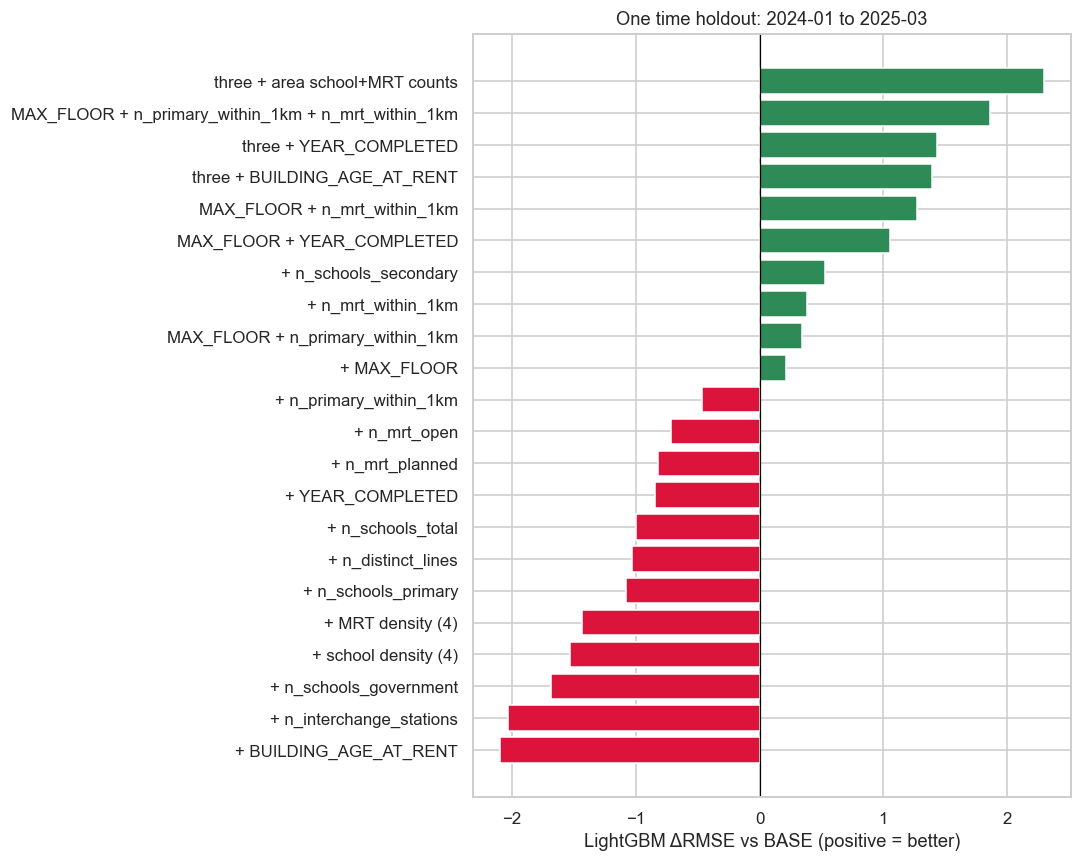

In [8]:
plot = pd.concat([singles, combos], ignore_index=True)
plot = plot[plot["spec"] != "BASE"].sort_values("d_lgb")
fig, ax = plt.subplots(figsize=(10, 8))
colors = np.where(plot["d_lgb"] >= 0, "seagreen", "crimson")
ax.barh(plot["spec"], plot["d_lgb"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("LightGBM ΔRMSE vs BASE (positive = better)")
ax.set_title("One time holdout: 2024-01 to 2025-03")
plt.tight_layout()
plt.show()


## 8. Verdict

- Keep the three if they beat BASE on LightGBM and beat the 1–2 feature stacks.
- Skip `YEAR_COMPLETED` / `BUILDING_AGE_AT_RENT` if they are worse vs BASE, and adding
  them to the three does not help.
- Skip area-level school/MRT counts if they are worse vs BASE, and stacking them on
  the three does not keep the 1 km gain.
- Keep the 11 SERS rows if dropping them from the BASE fit hurts.


In [9]:
def flag(delta, good="add", bad="skip"):
    if delta > 0.15:
        return good
    if delta < -0.15:
        return bad
    return "flat"


three = combos.set_index("spec").loc["MAX_FLOOR + n_primary_within_1km + n_mrt_within_1km"]
yc = singles.set_index("spec").loc["+ YEAR_COMPLETED"]
age = singles.set_index("spec").loc["+ BUILDING_AGE_AT_RENT"]
sch = singles.set_index("spec").loc["+ school density (4)"]
mrt4 = singles.set_index("spec").loc["+ MRT density (4)"]
drop_base = sers.iloc[1]["d_lgb_vs_keep"]

verdict = pd.DataFrame([
    {"claim": "Add MAX_FLOOR + n_primary_within_1km + n_mrt_within_1km",
     "lgb_delta": three["d_lgb"], "check": flag(three["d_lgb"], "supported", "not supported")},
    {"claim": "Do not add YEAR_COMPLETED",
     "lgb_delta": yc["d_lgb"], "check": flag(-yc["d_lgb"], "supported", "revisit") if yc["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Do not add BUILDING_AGE_AT_RENT",
     "lgb_delta": age["d_lgb"], "check": flag(-age["d_lgb"], "supported", "revisit") if age["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Do not add area-level school counts",
     "lgb_delta": sch["d_lgb"], "check": flag(-sch["d_lgb"], "supported", "revisit") if sch["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Do not add area-level MRT counts",
     "lgb_delta": mrt4["d_lgb"], "check": flag(-mrt4["d_lgb"], "supported", "revisit") if mrt4["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Keep the 11 SERS blocks in training",
     "lgb_delta": drop_base, "check": "supported (dropping BASE fit hurts)" if drop_base < -0.15 else "revisit"},
])
verdict.to_csv(OUT / "feature_rmse_verdict.csv", index=False)
pd.concat([singles, combos], ignore_index=True).to_csv(OUT / "feature_rmse_holdout.csv", index=False)
verdict


,claim,lgb_delta,check
0,Add MAX_FLOOR + n_primary_within_1km + n_mrt_w...,1.866,supported
1,Do not add YEAR_COMPLETED,-0.843,supported
2,Do not add BUILDING_AGE_AT_RENT,-2.099,supported
3,Do not add area-level school counts,-1.534,supported
4,Do not add area-level MRT counts,-1.438,supported
5,Keep the 11 SERS blocks in training,-2.487,supported (dropping BASE fit hurts)


### What this holdout actually showed

LightGBM BASE RMSE ≈ **496.4** (LR 657). Δ = BASE − this set. Positive = better.
One split: fit Jan 2021 to Dec 2023, score Jan 2024 to Mar 2025.

**What works:** keep `MAX_FLOOR`, `n_primary_within_1km`, and `n_mrt_within_1km` (Δ **+1.87**).

**What to skip on their own:** completion year, building age, and area-level totals — each
lands below BASE by itself, since `TOWN` already soaks up broad neighborhood effects. Stacked
*on top of* the three, area totals add a further +0.44 — real, but the smallest gain of
anything tested here.

**Keep the SERS rows:** they do not appear in validation, but dropping them from the BASE
fit costs **−2.49**. Leave height as NaN. LightGBM does not fill it. Linear Regression
only fills a median when `MAX_FLOOR` is in that spec.

Net impact: about **$1.87** off the LightGBM RMSE.

*(Updated from an earlier +2.76 / +0.07 — the school-coordinate fixes in `01_eda_school.ipynb`
changed `n_primary_within_1km` for blocks near the corrected schools, which shifted these
numbers. See `06_distance_features.ipynb` for the distance-feature follow-up.)*